#   Automatically generating spike test limits
The **spike test** flags points that jump away from their neighbors and straight back. It needs a `suspect_threshold` and a `fail_threshold`, in the units of your data, and those are hard to choose if you don't know what a normal jump looks like for your sensor and site.

This notebook runs `spike_thresh` from the `auto_limits` module on the same water level record as the AutoLimits example, and plots the result.

**TL;DR: Skip to the end for recommendations on getting started with unknown spike limits.**

##  Setup
Download the example data: water level at Belhaven, North Carolina, from SECOORA's ERDDAP server. The record is about 2.7 years long, sampled every 6 minutes.

In [1]:
import pandas as pd
import pooch

from ioos_qc.auto_limits import spike_thresh
from ioos_qc.plotting import plot_limits

# Belhaven, NC water level from SECOORA ERDDAP (CSV; row 2 holds units).
# pooch caches the file in the OS cache dir (e.g. ~/.cache/ioos_qc), not in the repo.
url = (
    "https://erddap.secoora.org/erddap/tabledap/belhaven-nc.csv"
    "?time%2Cwater_surface_above_navd88%2Cwater_surface_above_navd88_qc_agg%2Cz"
    "&time%3E%3D2024-03-06T20%3A18%3A15Z&time%3C%3D2026-11-17T20%3A24%3A00Z"
)
fname = pooch.retrieve(
    url,
    known_hash="sha256:9ec8f78ae59a611da71d1fe4ed62446f1442daf628777f63507d7018a995a1c9",
    fname="belhaven-nc.csv",
    path=pooch.os_cache("ioos_qc"),
)
df = pd.read_csv(fname, skiprows=[1], parse_dates=["time"])

water_level = df["water_surface_above_navd88"].to_numpy()         # meters, NAVD88
time = df["time"].dt.tz_convert("UTC").dt.tz_localize(None)       # pandas Series, tz-naive UTC
existing_qc = df["water_surface_above_navd88_qc_agg"].to_numpy()  # aggregate QARTOD flags (1/3/4)

##  Estimate the thresholds
`spike_thresh` scores every point against its two neighbors, the same way `spike_test` does, and sets each threshold well above the typical score: the median plus `k` times a robust measure of spread (the scaled MAD). The defaults, `suspect_k=35` and `fail_k=50`, are deliberately high because spikes are rare.

It returns one set of thresholds (in meters here) for each of the spike test's two methods, `average` and `differential`:

In [2]:
spike_limits = spike_thresh(water_level, include_fail_threshold=True)
spike_limits

{'average': {'suspect_threshold': 0.1332275000000001,
  'fail_threshold': 0.18882500000000016},
 'differential': {'suspect_threshold': 0.15967299999999435,
  'fail_threshold': 0.22638999999999193}}

##  Plot the results
`plot_limits` takes the thresholds directly; `spike_method` picks the method. The top panel shows the data and the flagged points. The bottom panel shows each point's spike score, with the thresholds as dashed lines.

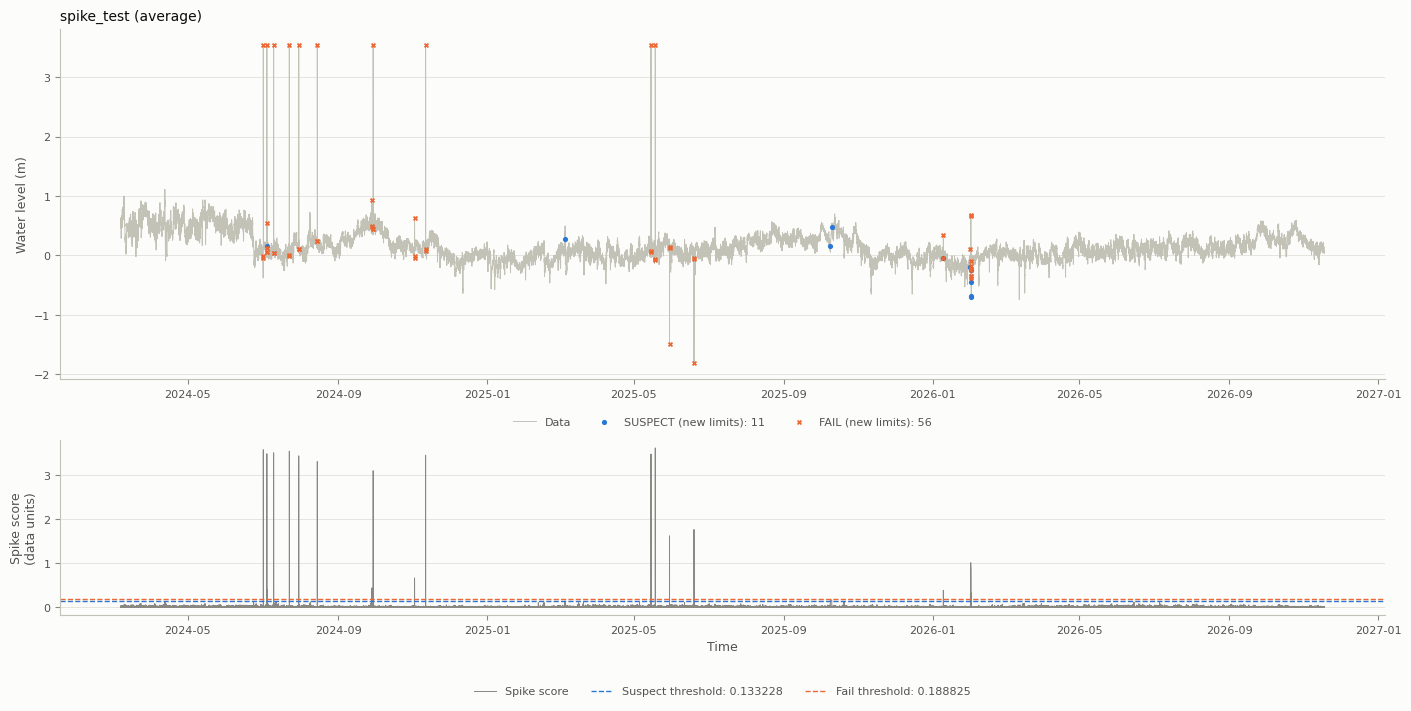

In [3]:
fig = plot_limits(water_level, time, spike_limits, spike_method="average", ylabel="Water level (m)")

Only a few dozen points are flagged in 2.7 years. The tallest are ten readings of exactly 3.548 m, which look like a sensor error code.

Zooming in on 1 February 2026 shows how the two methods differ:

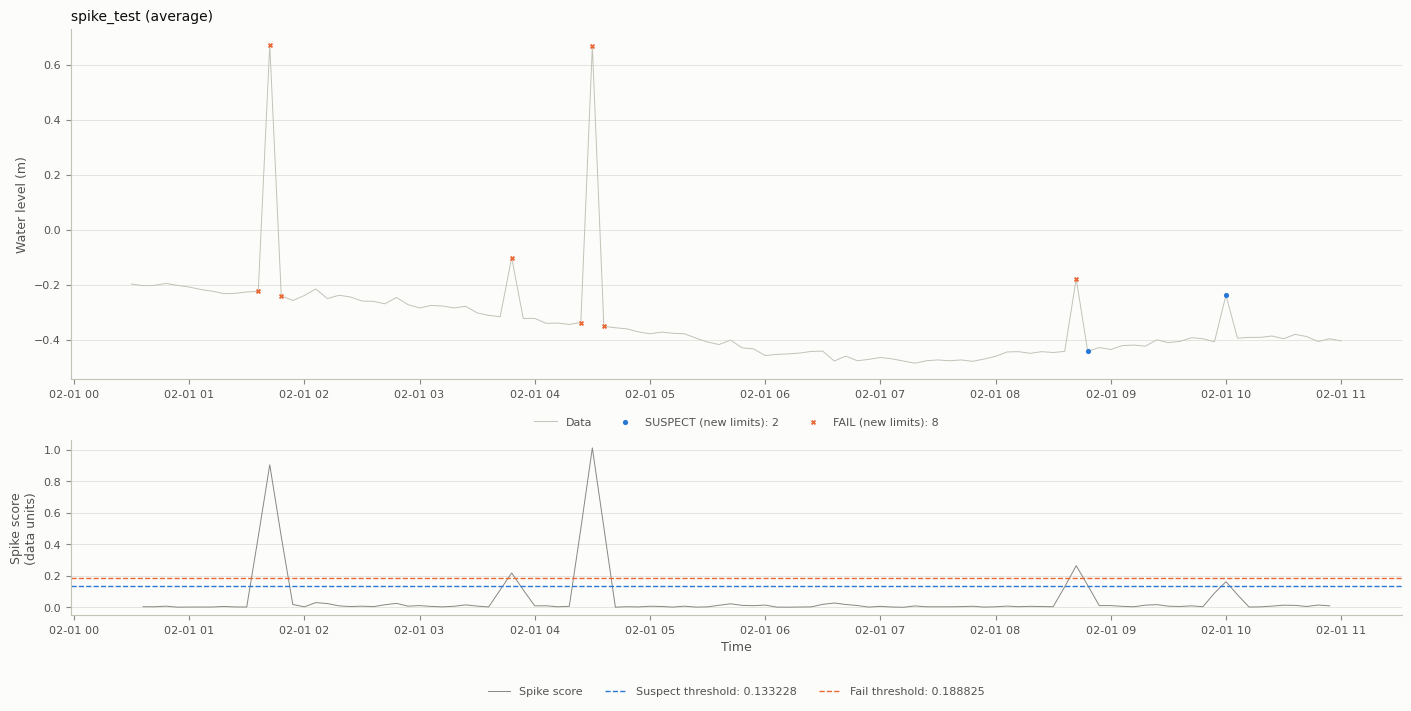

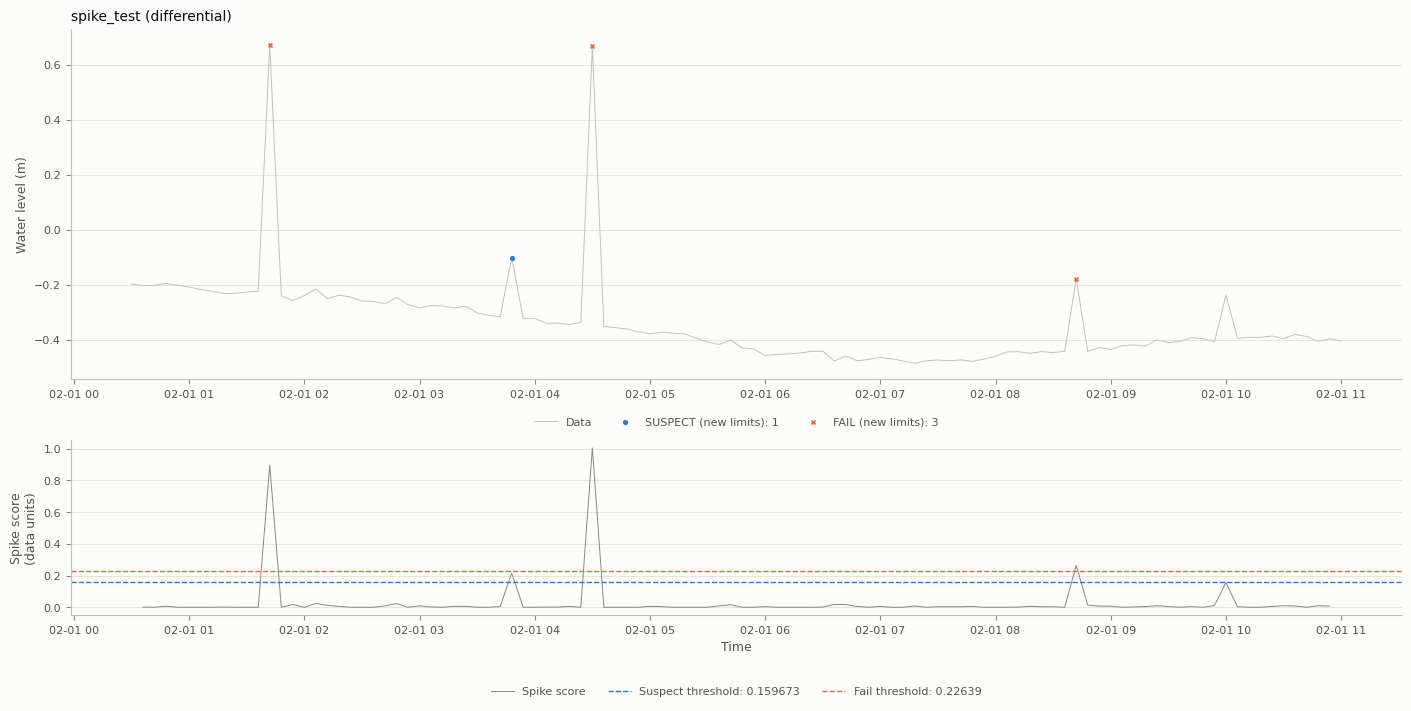

In [4]:
zoom = ((time >= "2026-02-01 00:30") & (time <= "2026-02-01 11:00")).to_numpy()

for method in ["average", "differential"]:
    plot_limits(water_level[zoom], time[zoom], spike_limits, spike_method=method, ylabel="Water level (m)")

Both methods catch the big spikes. `average` also flags the points either side of each spike, because their neighbor average includes the spike; `differential` flags only the spike itself.

##  Compare with existing QC
`reference=existing_qc` circles the station's existing flags and adds a confusion matrix and F1 score. The existing flags come from every test the operator ran, so a spike test alone won't match them all.

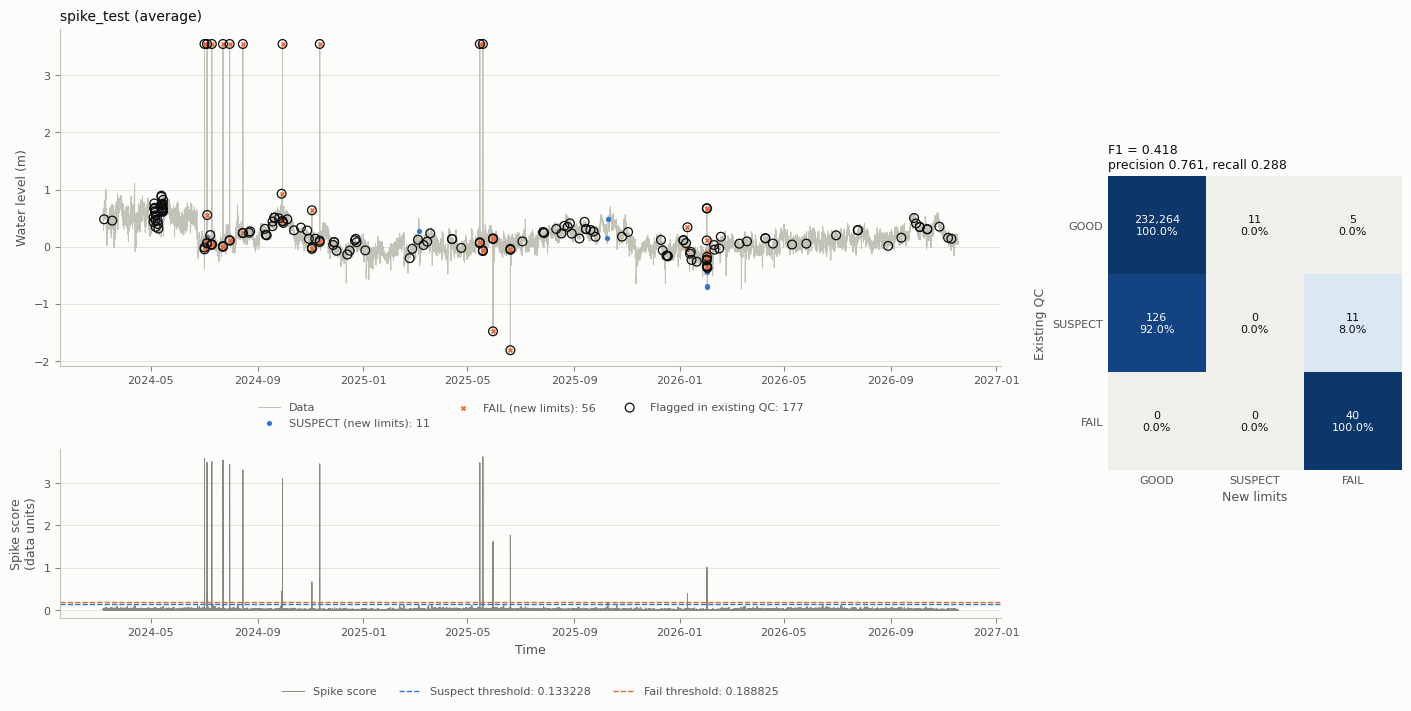

In [5]:
fig = plot_limits(water_level, time, spike_limits, spike_method="average", reference=existing_qc,
                  ylabel="Water level (m)")

##  Watch out for gaps
`spike_test` compares neighboring *rows*, regardless of time between them. Across this 27-hour gap the water level rose about 0.3 m, so both points next to the gap are flagged even though neither is wrong:

Longest gap in the record: 1 days 03:18:00


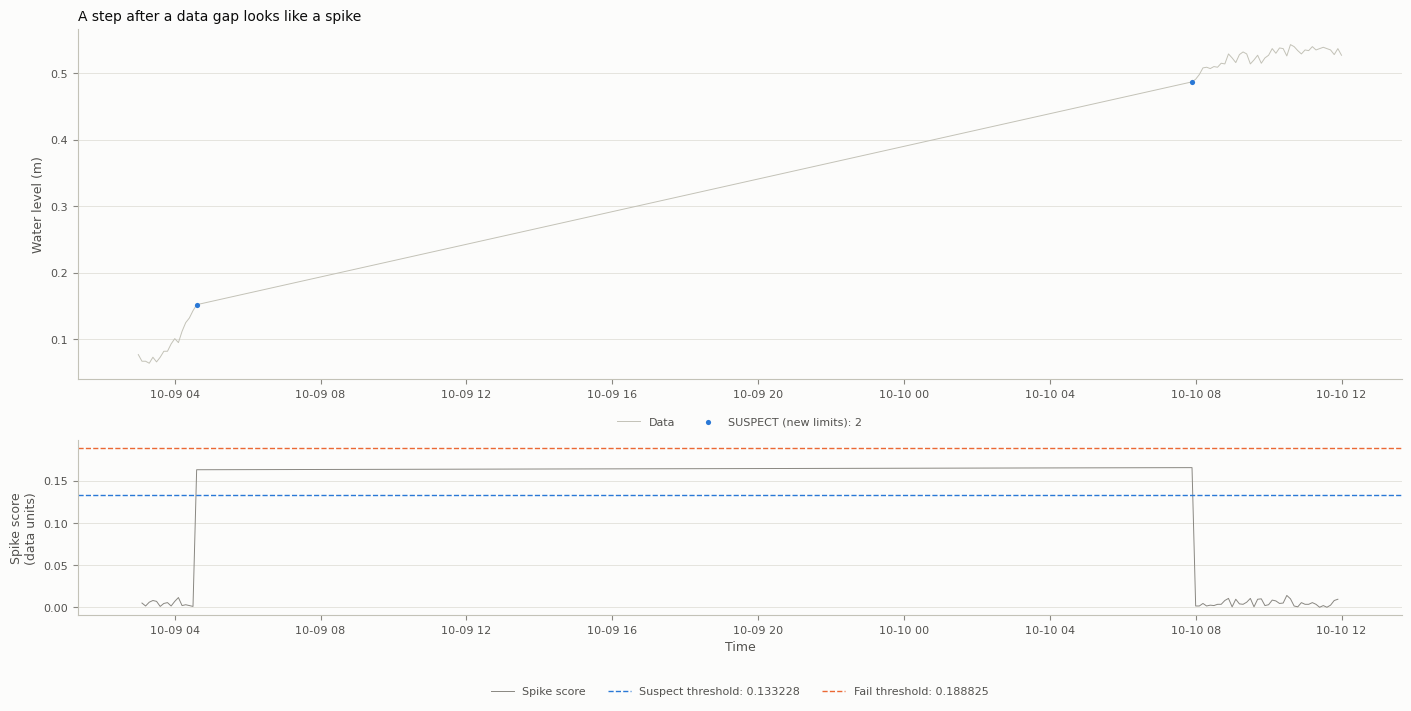

In [6]:
gap = ((time >= "2025-10-09 03:00") & (time <= "2025-10-10 12:00")).to_numpy()

plot_limits(water_level[gap], time[gap], spike_limits, title="A step after a data gap looks like a spike",
            ylabel="Water level (m)")
print(f"Longest gap in the record: {time.diff().max()}")

##  Conclusion and recommendations
If you don't know what your spike limits should be:

* Run `spike_thresh` on the raw data with the defaults, `suspect_k=35` and `fail_k=50`. Don't median-filter first: that removes the spikes you're looking for.
* Use the thresholds for the same `method` you run `spike_test` with; they are not interchangeable. `average` flags more points around each event, `differential` only the spike itself.
* Plot the result with `plot_limits` and zoom in on a few events. Increase `k` if ordinary variability is being flagged; decrease it if obvious spikes are missed.
* Check for gaps in the record: the spike test can't tell a gap from a jump.
* If you have existing QC flags, pass them as `reference` to see how well the new limits agree.

```python
#   Spike
limits = spike_thresh(var, include_fail_threshold=True)
flags = qartod.spike_test(var, method="average", **limits["average"])
fig = plot_limits(var, time, limits, spike_method="average")
```

As with the other tests, statistical limits are a starting point. Check them with people who know the sensor and the site.